# 04 — Débits (API RiverApp)

Stations et mesures via une API partenaire privée (`src/hydro.py`). Identifiants dans `.env`. Une station se désigne par son **identifiant RiverApp** (valable pour tous les pays) ; le code Hub'Eau sert seulement à le retrouver.

In [1]:
import sys
import tempfile
import time
from pathlib import Path

_racine = Path.cwd()
while not (_racine / "src").exists() and _racine != _racine.parent:
    _racine = _racine.parent
if str(_racine) not in sys.path:
    sys.path.insert(0, str(_racine))

import pandas as pd
import matplotlib.pyplot as plt
from src.hydro import RiverApp

CODE_HUBEAU = "X031001001"   # La Clapière (Durance à Embrun), station test

## 1. Mode d'emploi

Toutes les fonctions de `RiverApp`, en bref. Identifiants lus dans `.env`.

In [2]:
ra = RiverApp()                  # fournisseur par défaut : Hub'Eau
stations = ra.stations()         # liste des stations (index = identifiant RiverApp, colonne code = code chez le fournisseur)
ID = stations.query("code == @CODE_HUBEAU").index[0]
print("La Clapière :", ID)
stations.head(3)

La Clapière : 52a0c9cee4b03f58295e6f8a


,lat,lon,nom,cours_eau,plus_ancienne_mesure,code
id,,,,,,
52a0c9bee4b03f58295e6ec2,43.056603,2.216628,Limoux [Pont-de-Fer],Aude,2002-11-29 00:00:00+00:00,Y115201001
52a0c9bfe4b03f58295e6ec6,42.877783,2.184991,Quillan [Pont RD118],Aude,2013-11-19 00:00:00+00:00,Y111201002
52a0c9c0e4b03f58295e6ece,43.210373,2.358244,Carcassonne [Pont-Vieux],Aude,2000-01-01 00:00:00+00:00,Y123201001


In [3]:
# mesures brutes : débit (flow, m³/s) et hauteur (level, m), dates UTC ; ne télécharge que ce qui manque
ra.mesures(ID, "2024-10-01 00:00", "2024-10-01 02:00")

,flow,level
date,,
2024-10-01 00:00:00+00:00,47.700001,0.570
2024-10-01 00:45:00+00:00,47.400002,0.570
2024-10-01 01:00:00+00:00,47.299999,0.570
2024-10-01 01:45:00+00:00,46.799999,0.563
2024-10-01 02:00:00+00:00,46.799999,0.560


In [4]:
# une valeur toutes les 4 h, calée sur minuit UTC, interpolée linéairement entre les mesures voisines
ra.mesures(ID, "2024-10-01", "2024-10-02", pas="4h")

,flow,level
date,,
2024-10-01 00:00:00+00:00,47.700001,0.57
2024-10-01 04:00:00+00:00,46.900002,0.56
2024-10-01 08:00:00+00:00,0.200000,-0.04
2024-10-01 12:00:00+00:00,41.400002,0.52
2024-10-01 16:00:00+00:00,45.400002,0.55
2024-10-01 20:00:00+00:00,45.299999,0.55
2024-10-02 00:00:00+00:00,47.299999,0.57


In [5]:
# à travers un trou de plus de trou_max (3 h par défaut), la valeur reste vide ; trou_max l'élargit
pd.concat({"trou_max=3h": ra.mesures(ID, "2016-05-01", "2016-05-02", pas="4h").flow,
           "trou_max=24h": ra.mesures(ID, "2016-05-01", "2016-05-02", pas="4h", trou_max="24h").flow}, axis=1)

,trou_max=3h,trou_max=24h
date,,
2016-05-01 00:00:00+00:00,NaN,57.037498
2016-05-01 04:00:00+00:00,NaN,55.754166
2016-05-01 08:00:00+00:00,NaN,54.470833
2016-05-01 12:00:00+00:00,NaN,53.837502
2016-05-01 16:00:00+00:00,NaN,53.420834
2016-05-01 20:00:00+00:00,NaN,53.004169
2016-05-02 00:00:00+00:00,NaN,52.275002


In [6]:
# filtre=True : retire les pics isolés (erreurs du capteur) avant de calculer ; le cache reste brut
pd.concat({"brut": ra.mesures(ID, "2024-10-01 06:00", "2024-10-01 10:00", pas="1h").flow,
           "filtré": ra.mesures(ID, "2024-10-01 06:00", "2024-10-01 10:00", pas="1h", filtre=True).flow}, axis=1)

,brut,filtré
date,,
2024-10-01 06:00:00+00:00,46.000000,46.000000
2024-10-01 07:00:00+00:00,18.500000,18.500000
2024-10-01 08:00:00+00:00,0.200000,34.328571
2024-10-01 09:00:00+00:00,45.900002,45.900002
2024-10-01 10:00:00+00:00,45.700001,45.700001


In [7]:
ra.contenu_cache()               # ce qui est en cache ; ra.vider_cache([ID]) le viderait (cf. dernière section)

,id,code,debut,fin,mesures,mo
0,52a0c9cee4b03f58295e6f8a,X031001001,2010-04-02 00:00:00+00:00,2026-10-07 02:16:00+00:00,362170,3.55


## 2. Stations Hub'Eau

3096 stations


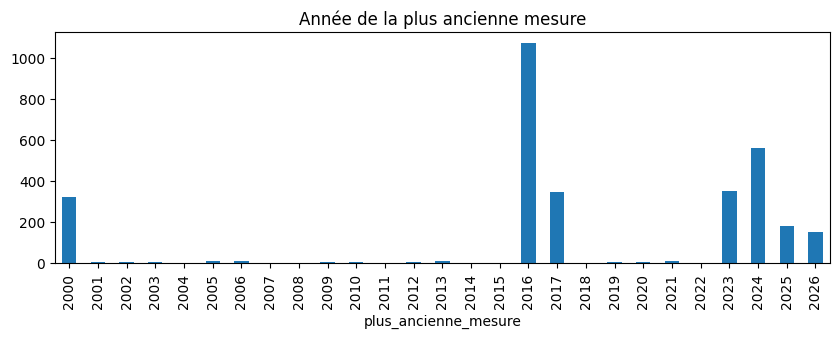

,lat,lon,nom,cours_eau,plus_ancienne_mesure,code
id,,,,,,
52a0c9cee4b03f58295e6f8a,44.55536,6.498014,Embrun [La Clapière],Durance,2010-04-02 00:00:00+00:00,X031001001


In [8]:
print(f"{len(stations)} stations")
stations.plus_ancienne_mesure.dt.year.value_counts().sort_index().plot.bar(figsize=(10, 3), title="Année de la plus ancienne mesure")
plt.show()
stations.loc[[ID]]

Un même code Hub'Eau peut correspondre à deux stations RiverApp (ici Langon) : d'où l'identifiant RiverApp comme clé.

In [9]:
stations[stations.code.duplicated(keep=False)]

,lat,lon,nom,cours_eau,plus_ancienne_mesure,code
id,,,,,,
5a2e6c085782af5a46319138,44.557767,-0.238005,Langon [AIRBUS],Garonne [La Gironde],2017-12-08 00:00:00+00:00,O945001001
67f4f509a12554570cb5b949,44.556325,-0.246908,Langon,Garonne,2025-04-06 00:00:00+00:00,O945001001


## 3. Mesures de La Clapière

Tout l'historique, par tranches de 32 jours ; seul ce qui manque au cache est téléchargé.

In [10]:
t = time.time()
mesures = ra.mesures(ID)
print(f"{len(mesures):,} mesures, {mesures.index.min()} → {mesures.index.max()} ({time.time() - t:.1f} s)")
mesures.tail()

362,170 mesures, 2010-04-02 01:00:00+00:00 → 2026-10-07 02:00:00+00:00 (0.0 s)


,flow,level
date,,
2026-10-06 23:45:00+00:00,15.3,0.233
2026-10-07 00:00:00+00:00,15.4,0.234
2026-10-07 00:15:00+00:00,15.4,0.234
2026-10-07 00:30:00+00:00,15.4,0.234
2026-10-07 02:00:00+00:00,15.3,0.230


## 4. Nature des données par année

Avant le 29/03/2016 : débit horaire seul. Après : débit + hauteur toutes les 15 min. Avril-octobre 2016 : ~2 mesures par jour.

In [11]:
pas = mesures.index.to_series().diff().dt.total_seconds().div(60).values
mesures.assign(pas_min=pas).groupby(mesures.index.year).agg(
    mesures=("flow", "size"), debit=("flow", lambda x: round(x.notna().mean(), 2)),
    hauteur=("level", lambda x: round(x.notna().mean(), 2)), pas_median_min=("pas_min", "median"))

,mesures,debit,hauteur,pas_median_min
date,,,,
2010,5110,1.0,0.00,60.0
2011,3298,1.0,0.00,60.0
2012,8784,1.0,0.00,60.0
2013,8760,1.0,0.00,60.0
2014,8015,1.0,0.00,60.0
2015,8760,1.0,0.00,60.0
2016,4966,1.0,0.64,15.0
2017,31884,1.0,1.00,15.0
2018,34871,1.0,1.00,15.0


## 5. Débit horaire

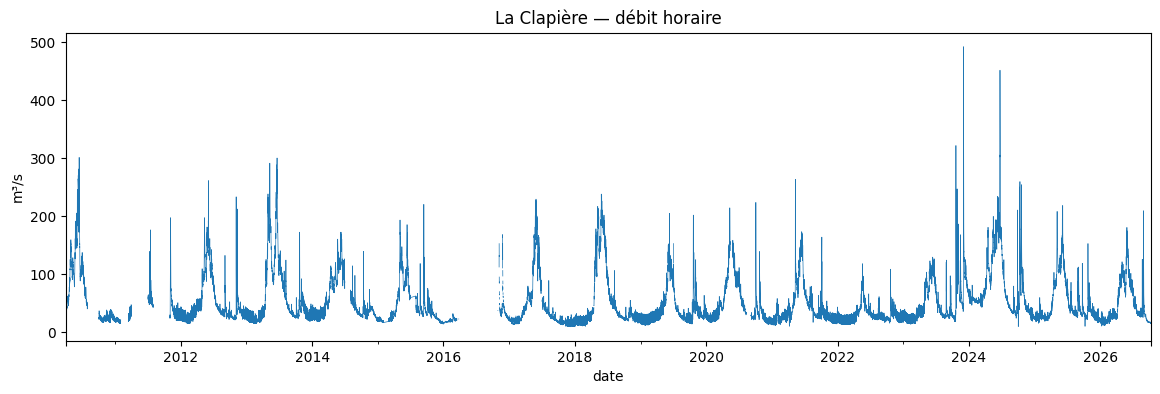

heures sans débit (%) : {2010: 22.3, 2011: 62.4, 2012: 0.0, 2013: 0.0, 2014: 8.5, 2015: 0.0, 2016: 65.2, 2017: 7.9, 2018: 0.5, 2019: 1.2, 2020: 11.7, 2021: 1.5, 2022: 0.0, 2023: 0.0, 2024: 0.2, 2025: 1.1, 2026: 0.6}


In [12]:
horaire = mesures.flow.resample("1h").mean()
horaire.plot(figsize=(14, 4), lw=0.5, ylabel="m³/s", title="La Clapière — débit horaire")
plt.show()
print("heures sans débit (%) :", (horaire.isna().groupby(horaire.index.year).mean() * 100).round(1).to_dict())

## 6. Valeurs suspectes et filtre

`filtre=True` vide une mesure qui s'écarte de plus de 50 % à la fois de la médiane de l'heure et demie d'avant et de celle d'après, dans le même sens. Le bord d'une vraie montée (lâcher, crue) ressemble à l'un des deux côtés : il est gardé. À 30 %, les lâchers d'hiver (13 → 27 m³/s) étaient retirés à tort.

6 mesures, jours : [datetime.date(2024, 10, 1), datetime.date(2025, 10, 7), datetime.date(2026, 8, 25)]


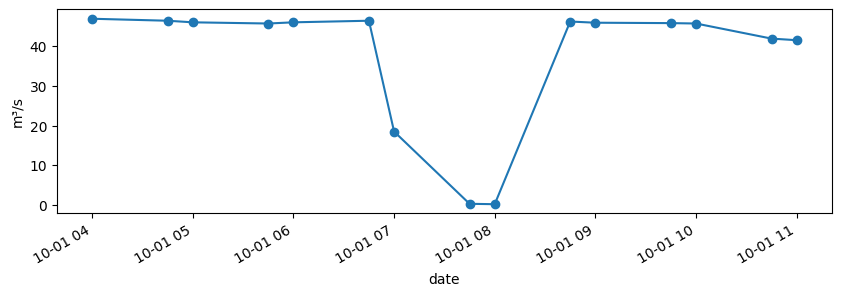

In [13]:
suspect = mesures[mesures.flow < 3]
print(len(suspect), "mesures, jours :", sorted(set(suspect.index.date)))
mesures.flow.loc["2024-10-01 04:00":"2024-10-01 11:00"].plot(marker="o", figsize=(10, 3), ylabel="m³/s")
plt.show()

In [14]:
brut, filtre = ra.mesures(ID), ra.mesures(ID, filtre=True)
retirees = brut[brut.flow.notna() & filtre.flow.isna()]
print(f"{len(retirees)} mesures retirées sur {brut.flow.notna().sum():,}")
retirees

17 mesures retirées sur 362,164


,flow,level
date,,
2020-05-27 11:00:00+00:00,56.700001,0.770
2021-01-26 21:15:00+00:00,41.799999,0.610
2021-04-08 09:15:00+00:00,19.100000,0.340
2021-08-17 12:30:00+00:00,14.100000,0.200
2021-08-17 12:45:00+00:00,5.700000,-0.020
2021-08-17 13:00:00+00:00,5.100000,-0.040
2022-10-12 12:00:00+00:00,5.800000,-0.010
2023-07-11 13:45:00+00:00,5.300000,-0.030
2023-07-11 14:00:00+00:00,5.500000,-0.030


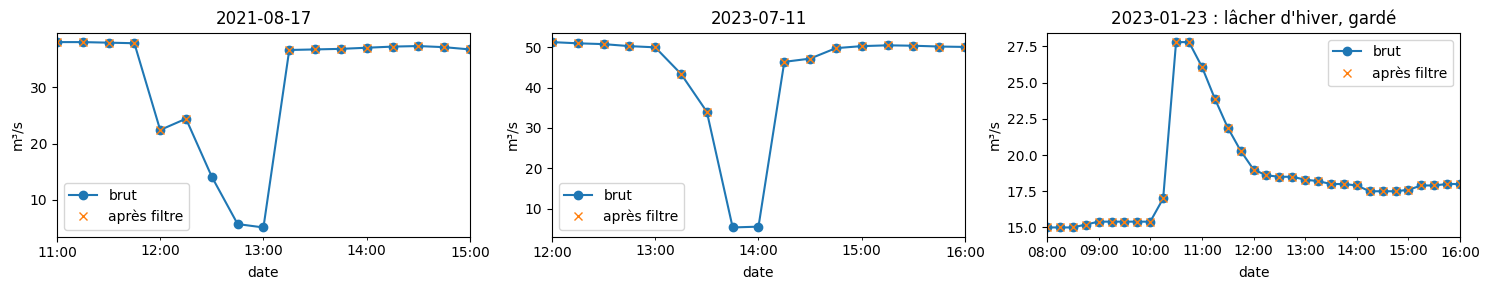

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, (d0, d1) in zip(axes, [("2021-08-17 11:00", "2021-08-17 15:00"), ("2023-07-11 12:00", "2023-07-11 16:00"),
                              ("2023-01-23 08:00", "2023-01-23 16:00")]):
    brut.flow.loc[d0:d1].plot(ax=ax, marker="o", label="brut")
    filtre.flow.loc[d0:d1].plot(ax=ax, marker="x", ls="", label="après filtre")
    ax.set_title(d0[:10]); ax.set_ylabel("m³/s"); ax.legend()
axes[2].set_title("2023-01-23 : lâcher d'hiver, gardé")
plt.tight_layout(); plt.show()

## 7. Pas régulier

`pas` : grille calée sur minuit UTC, interpolation linéaire dans le temps, vide si les deux mesures qui encadrent l'instant sont à plus de `trou_max` (3 h par défaut).

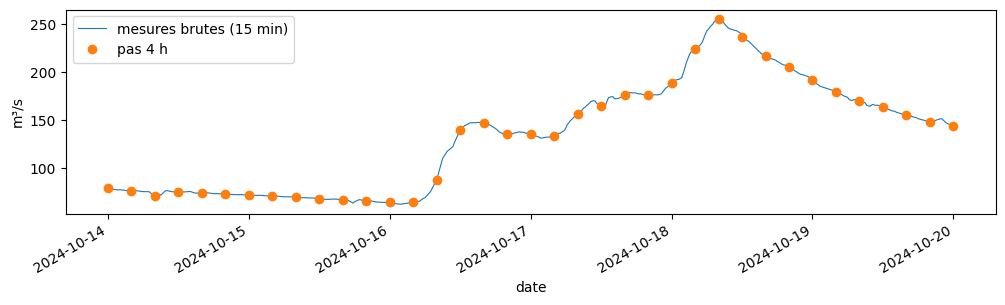

,flow,level
date,,
2024-10-14 00:00:00+00:00,78.900002,0.79
2024-10-14 04:00:00+00:00,76.199997,0.77
2024-10-14 08:00:00+00:00,70.599998,0.74
2024-10-14 12:00:00+00:00,75.000000,0.77
2024-10-14 16:00:00+00:00,74.099998,0.76


In [16]:
brut = ra.mesures(ID, "2024-10-14", "2024-10-20")
quatre = ra.mesures(ID, "2024-10-14", "2024-10-20", pas="4h")
ax = brut.flow.plot(figsize=(12, 3), lw=0.8, label="mesures brutes (15 min)")
quatre.flow.plot(ax=ax, marker="o", ls="", label="pas 4 h")
ax.set_ylabel("m³/s"); ax.legend(); plt.show()
quatre.head()

In [17]:
for trou in ("3h", "24h"):
    x = ra.mesures(ID, "2016-04-15", "2016-09-30", pas="4h", trou_max=trou)
    print(f"avril-septembre 2016 (≈ 2 mesures/jour), trou_max={trou} : {x.flow.notna().mean():.0%} de valeurs")

avril-septembre 2016 (≈ 2 mesures/jour), trou_max=3h : 0% de valeurs
avril-septembre 2016 (≈ 2 mesures/jour), trou_max=24h : 100% de valeurs


## 8. Cache

In [18]:
ra.contenu_cache()

,id,code,debut,fin,mesures,mo
0,52a0c9cee4b03f58295e6f8a,X031001001,2010-04-02 00:00:00+00:00,2026-10-07 02:16:00+00:00,362170,3.55


`vider_cache`, sur un cache temporaire (2 jours de mesures) pour ne pas toucher au vrai.

In [19]:
essai = RiverApp(dossier=tempfile.mkdtemp())
essai.mesures(ID, "2023-06-01", "2023-06-03")
print("avant :", len(essai.contenu_cache()), "station(s)")
essai.vider_cache()
print("après :", len(essai.contenu_cache()), "station(s)")

avant : 1 station(s)
après : 0 station(s)
